# Esercitazione 2 — K-Nearest Neighbors (KNN)

KNN classifica un punto guardando le **K classi dei vicini più prossimi** nel training set (voto di maggioranza, eventualmente pesato).
Non c'è una vera fase di "training": il modello memorizza i dati (*lazy learner*).

Punti chiave:
- si basa sulle **distanze** → il **Feature Scaling è fondamentale**;
- **K** è l'iperparametro principale: K piccolo → alta varianza (overfitting); K grande → alto bias (underfitting);
- lo sceglieremo con **cross-validation a 10 fold** e con il **metodo Elbow**.

## 0. Setup e importazioni

In [1]:
# Import delle librerie di base
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Moduli di scikit-learn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # seme fisso per la riproducibilità

## 1. Caricamento del dataset (Iris)

In [2]:
iris = load_iris()
X, y = iris.data, iris.target
target_names = iris.target_names
feature_names = iris.feature_names

pd.DataFrame(X, columns=feature_names).describe().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


## 2. Suddivisione in Training (70%) e Test (30%)

In [3]:
# Split 70% train / 30% test.
# random_state=42 -> risultato riproducibile; stratify=y -> stesse proporzioni di classi in train e test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (105, 4) | Test: (45, 4)


## Feature Scaling con `StandardScaler`

`StandardScaler` trasforma ogni feature in modo che abbia media 0 e deviazione standard 1: $z = (x - \mu)/\sigma$.

**Regola fondamentale:**
1. `fit_transform` sul **training set**: lo scaler *impara* media e deviazione standard dai soli dati di training e li applica.
2. `transform` sul **test set**: si riusano gli stessi $\mu$ e $\sigma$ del training.

Se facessimo `fit` anche sul test (o sull'intero dataset) useremmo informazioni che nella realtà non abbiamo ancora: è il **data leakage**, che rende le stime di performance troppo ottimistiche. Il test set deve simulare dati *mai visti*.


    > **Perché per KNN?** Con la distanza euclidea una feature con scala maggiore domina il calcolo. Dopo lo scaling tutte le feature contribuiscono in modo equo.

In [4]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)  # fit + transform sul train
X_test_s = scaler.transform(X_test)        # solo transform sul test

## 3. Ricerca del K ottimale: Cross-Validation (10-fold) ed Elbow Method

Per ogni K da 1 a 30 calcoliamo l'accuratezza media in 10-fold CV **sul solo training set** (il test set resta intoccato per la valutazione finale).
Poi tracciamo accuratezza media vs K: il K ottimale è dove la curva raggiunge il massimo / smette di migliorare significativamente (il "gomito").

In [5]:
k_range = range(1, 31)
cv_means, cv_stds = [], []

for k in k_range:
    knn_k = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn_k, X_train_s, y_train, cv=10, scoring="accuracy")
    cv_means.append(scores.mean())
    cv_stds.append(scores.std())

cv_means, cv_stds = np.array(cv_means), np.array(cv_stds)

# K ottimale: massima accuratezza media (np.argmax sceglie il K più piccolo in caso di parità)
best_idx = int(np.argmax(cv_means))
k_opt = list(k_range)[best_idx]
print(f"K ottimale = {k_opt}  (accuracy CV media = {cv_means[best_idx]:.4f})")

K ottimale = 9  (accuracy CV media = 0.9718)


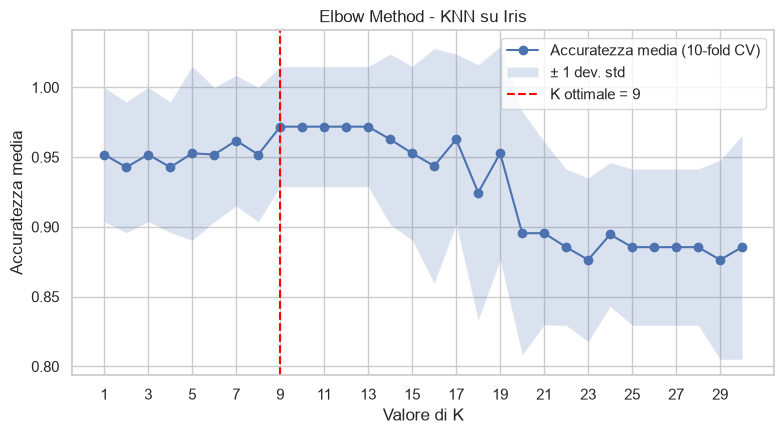

In [6]:
# Grafico Elbow
plt.figure(figsize=(8, 4.5))
plt.plot(list(k_range), cv_means, marker="o", label="Accuratezza media (10-fold CV)")
plt.fill_between(list(k_range), cv_means - cv_stds, cv_means + cv_stds, alpha=0.2, label="± 1 dev. std")
plt.axvline(k_opt, color="red", linestyle="--", label=f"K ottimale = {k_opt}")
plt.xlabel("Valore di K"); plt.ylabel("Accuratezza media")
plt.title("Elbow Method - KNN su Iris")
plt.xticks(range(1, 31, 2)); plt.legend()
plt.tight_layout(); plt.show()

## 4. Modello finale
Usiamo `K = k_opt`, voto **pesato per la distanza** (`weights='distance'`: i vicini più vicini contano di più) e metrica **euclidea**.

In [7]:
knn = KNeighborsClassifier(
    n_neighbors=k_opt,
    weights="distance",
    metric="euclidean",   # equivale a minkowski con p=2
)
knn.fit(X_train_s, y_train)       # addestramento (memorizza il training set)

y_pred = knn.predict(X_test_s)
y_proba = knn.predict_proba(X_test_s)

# Probabilità per i primi 5 campioni di test
pd.DataFrame(y_proba[:5], columns=[f"P({c})" for c in target_names]).round(3).assign(
    predetta=target_names[y_pred[:5]], vera=target_names[y_test[:5]])

,P(setosa),P(versicolor),P(virginica),predetta,vera
0,0.0,0.000,1.000,virginica,virginica
1,0.0,1.000,0.000,versicolor,versicolor
2,0.0,0.660,0.340,versicolor,virginica
3,0.0,0.669,0.331,versicolor,versicolor
4,0.0,0.397,0.603,virginica,virginica


## 5. Valutazione e matrice di confusione

Accuracy sul test set: 0.9333

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.83      1.00      0.91        15
   virginica       1.00      0.80      0.89        15

    accuracy                           0.93        45
   macro avg       0.94      0.93      0.93        45
weighted avg       0.94      0.93      0.93        45



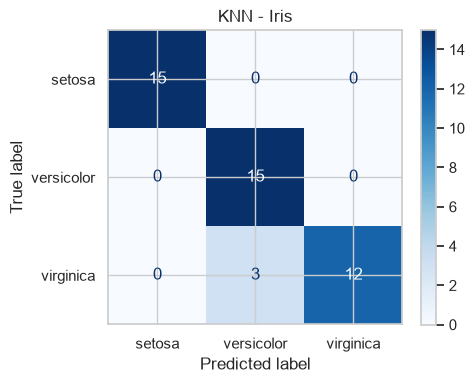

In [8]:
# Valutazione: accuracy, classification report e matrice di confusione
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy sul test set: {acc:.4f}\n")
print(classification_report(y_test, y_pred, target_names=target_names))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=target_names, cmap="Blues", ax=ax)
ax.set_title("KNN - Iris")
plt.tight_layout()
plt.show()

## 6. (Bonus) Confronto con e senza scaling
Verifica empirica dell'importanza dello scaling: stesso modello sui dati grezzi.

In [9]:
knn_raw = KNeighborsClassifier(n_neighbors=k_opt, weights="distance", metric="euclidean").fit(X_train, y_train)
print(f"Accuracy SENZA scaling: {accuracy_score(y_test, knn_raw.predict(X_test)):.4f}")
print(f"Accuracy CON scaling:   {accuracy_score(y_test, y_pred):.4f}")
# Su Iris la differenza è piccola perché le feature hanno scale simili (cm);
# su dataset con scale molto diverse (es. età e reddito) lo scaling cambia drasticamente i risultati.

Accuracy SENZA scaling: 0.9556
Accuracy CON scaling:   0.9333


## Riepilogo
- KNN dipende dalle distanze → `StandardScaler` (fit sul train, transform sul test).
- K scelto con 10-fold CV sul train + grafico Elbow.
- `weights='distance'` pesa i vicini in base alla vicinanza; `metric='euclidean'` è la distanza classica.

**Esercizi proposti:** prova `metric='manhattan'`, `weights='uniform'`, il dataset `load_wine()` (scale molto diverse!) e `GridSearchCV` per cercare K, pesi e metrica insieme.